# 06 — Backtesting, benchmark MS-GARCH e hipóteses

Quatro modelos, avaliados nos mesmos 2.717 pregões de teste (out/2012 a mar/2024):

| modelo | média do retorno | volatilidade | cauda |
|---|---|---|---|
| **HMM-LSTM** | LSTM com regime do HMM | EWMA | erros da calibração (do regime, se houver ≥100) |
| **LSTM** | LSTM sem regime | EWMA | erros da calibração |
| **FHS-EWMA** | zero | EWMA | erros da calibração |
| **MS-GARCH** | zero | MS-GARCH(1,1) Student-t, 2 estados | resíduos do desenvolvimento |

O MS-GARCH (Haas; Mittnik; Paolella, 2004) é estimado no R com o pacote MSGARCH (Ardia et
al., 2019): `scripts/msgarch_inputs.py` → `r/msgarch_benchmark.R` →
`scripts/msgarch_forecasts.py`. Em cada janela, ele é ajustado só nos cinco anos de
desenvolvimento, o número de estados (2 ou 3) é escolhido pelo BIC e os parâmetros ficam
congelados no teste. A previsão de cada dia usa os retornos até a véspera.

Os testes:
- **Kupiec (1995)**: a frequência de violações bate com a nominal?
- **Christoffersen (1998)**: as violações aparecem agrupadas?
- **Acerbi e Székely (2014), Z2**: o ES subestima a severidade das perdas? O p-valor vem de
  999 trajetórias sorteadas da distribuição que o próprio modelo previu.
- **Diebold e Mariano (1995)**: comparação pareada de dois escores, o quantílico (só VaR) e o
  FZ0 de Fissler e Ziegel (2016), que avalia VaR e ES juntos. Menor é melhor; usa HAC com 5
  defasagens.

O **estresse** é o estado de maior volatilidade do HMM na véspera, e os dias de todos os
modelos são separados por esse mesmo critério. A avaliação roda em
`scripts/evaluate_walk_forward.py`, e este notebook lê as tabelas que ele gera.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.features import get_b3_trading_days
from src.risk.backtests import var_coverage

RESULTS_DIR = PROJECT_ROOT / "reports" / "tables" / "walk_forward"
EVAL_DIR = RESULTS_DIR / "evaluation_v3"
MSGARCH_DIR = PROJECT_ROOT / "reports" / "tables" / "msgarch"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False})
NAMES = {"hmm_lstm": "HMM-LSTM", "lstm": "LSTM", "zero_mean_reference": "FHS-EWMA", "ms_garch": "MS-GARCH"}
ORDER = list(NAMES.values())
SEGMENTS = {"todos": "todos os dias", "estresse": "estresse", "demais_regimes": "demais regimes"}

if not (EVAL_DIR / "backtest_cobertura.csv").exists():
    subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "evaluate_walk_forward.py")], check=True)
coverage = pd.read_csv(EVAL_DIR / "backtest_cobertura.csv")
dm = pd.read_csv(EVAL_DIR / "backtest_comparacao_dm.csv")
summary = json.loads((EVAL_DIR / "backtest_resumo.json").read_text(encoding="utf-8"))
coverage["modelo"] = coverage.modelo.map(NAMES)
for col in ("a", "b"):
    dm[col] = dm[col].map(NAMES)
print(json.dumps({k: summary[k] for k in ("periodo_teste", "n_janelas", "dias_de_teste", "dias_em_estresse",
                                          "benchmarks", "es_simulations")}, ensure_ascii=False))

{"periodo_teste": ["2012-10-01", "2024-03-27"], "n_janelas": 23, "dias_de_teste": 2717, "dias_em_estresse": 289, "benchmarks": ["ms_garch"], "es_simulations": 999}


## O benchmark: ajuste do MS-GARCH

In [2]:
fits = pd.read_parquet(MSGARCH_DIR / "msgarch_fits.parquet")
bic = fits.pivot(index="fold", columns="K", values="bic").rename(columns=lambda k: f"BIC K={k}")
bic["escolhido"] = fits.loc[fits.groupby("fold").bic.idxmin(), ["fold", "K"]].set_index("fold").K
print(f"K=3 convergiu em {fits.query('K == 3').converged.sum()} de {fits.fold.nunique()} janelas; "
      f"onde convergiu, o BIC preferiu K=2 em {(bic['BIC K=2'] < bic['BIC K=3']).sum()}.")
pars = fits[fits.K == 2].set_index("fold").par.map(json.loads).apply(pd.Series)
for k in (1, 2):
    pars[f"persistência_{k}"] = pars[f"alpha1_{k}"] + pars[f"beta_{k}"]
    pars[f"vol_incond_anual_{k}_%"] = np.sqrt(pars[f"alpha0_{k}"] / (1 - pars[f"persistência_{k}"]) * 252)
display(bic.round(1).head())
pars[["persistência_1", "persistência_2", "vol_incond_anual_1_%", "vol_incond_anual_2_%",
      "nu_1", "nu_2", "P_1_1", "P_2_1"]].describe().loc[["50%", "min", "max"]].rename(index={"50%": "mediana"}).round(3)

K=3 convergiu em 14 de 23 janelas; onde convergiu, o BIC preferiu K=2 em 14.


K,BIC K=2,BIC K=3,escolhido
fold,,,
0,4127.8,4178.9,2
1,4053.9,4105.8,2
2,4032.1,NaN,2
3,3772.3,NaN,2
4,3664.8,3717.1,2


,persistência_1,persistência_2,vol_incond_anual_1_%,vol_incond_anual_2_%,nu_1,nu_2,P_1_1,P_2_1
mediana,0.971,0.891,15.450,25.364,11.927,12.704,0.991,0.042
min,0.254,0.078,10.465,20.727,6.612,3.530,0.798,0.009
max,0.994,1.000,17.972,531.453,99.680,99.725,0.999,0.225


Em todas as janelas, o BIC fica com dois estados: um de volatilidade baixa e outro de
volatilidade alta (vol. incondicional mediana de cerca de 15% e 25% ao ano; a do estado
alto dispara nas poucas janelas em que sua persistência chega perto de 1). O estado de baixa
volatilidade é muito persistente (P₁₁ mediano de 0,99). Com três estados, o pacote falhou em parte das janelas por um erro numérico
nos valores iniciais. Onde convergiu, perdeu no BIC, então a escolha não depende dessas
falhas. Os parâmetros completos estão em `reports/tables/msgarch/msgarch_fits.parquet`.

## Cobertura do VaR

In [3]:
def table(level):
    t = coverage[coverage.nivel == level].copy()
    t["segmento"] = t.segmento.map(SEGMENTS)
    t["violações"] = t.apply(lambda r: f"{int(r.violacoes)}/{int(r.n)} ({r.taxa:.1%})", axis=1)
    t = t.set_index(["segmento", "modelo"])[["violações", "esperado", "kupiec_p", "independencia_p",
                                             "cobertura_cond_p"]]
    t.columns = ["violações", "esperadas", "Kupiec p", "independência p", "cob. condicional p"]
    return t.reindex(pd.MultiIndex.from_product([SEGMENTS.values(), ORDER])).round(3)

print("VaR 95%"); display(table(.95))
print("VaR 99%"); display(table(.99))

VaR 95%


violações  esperadas  Kupiec p  \
todos os dias  HMM-LSTM  142/2717 (5.2%)     135.85     0.591   
               LSTM      142/2717 (5.2%)     135.85     0.591   
               FHS-EWMA  138/2717 (5.1%)     135.85     0.850   
               MS-GARCH  127/2717 (4.7%)     135.85     0.431   
estresse       HMM-LSTM    23/289 (8.0%)      14.45     0.033   
               LSTM        22/289 (7.6%)      14.45     0.058   
               FHS-EWMA    19/289 (6.6%)      14.45     0.240   
               MS-GARCH    19/289 (6.6%)      14.45     0.240   
demais regimes HMM-LSTM  119/2428 (4.9%)     121.40     0.823   
               LSTM      120/2428 (4.9%)     121.40     0.896   
               FHS-EWMA  119/2428 (4.9%)     121.40     0.823   
               MS-GARCH  108/2428 (4.4%)     121.40     0.204   

                         independência p  cob. condicional p  
todos os dias  HMM-LSTM            0.541               0.718  
               LSTM                0.541               0.718  
               FHS-EWMA            0.693               0.909  
               MS-GARCH            0.387               0.505  
estresse       HMM-LSTM            0.481               0.080  
               LSTM                0.558               0.139  
               FHS-EWMA            0.106               0.136  
               MS-GARCH            0.106               0.136  
demais regimes HMM-LSTM            0.349               0.629  
               LSTM                0.373               0.666  
               FHS-EWMA            0.913               0.969  
               MS-GARCH            0.721               0.419

VaR 99%


violações  esperadas  Kupiec p  independência p  \
todos os dias  HMM-LSTM  30/2717 (1.1%)      27.17     0.591            0.411   
               LSTM      30/2717 (1.1%)      27.17     0.591            0.411   
               FHS-EWMA  30/2717 (1.1%)      27.17     0.591            0.345   
               MS-GARCH  26/2717 (1.0%)      27.17     0.820            0.477   
estresse       HMM-LSTM    7/289 (2.4%)       2.89     0.040            0.579   
               LSTM        7/289 (2.4%)       2.89     0.040            0.579   
               FHS-EWMA    8/289 (2.8%)       2.89     0.013            0.521   
               MS-GARCH    6/289 (2.1%)       2.89     0.108            0.608   
demais regimes HMM-LSTM  23/2428 (0.9%)      24.28     0.792            0.514   
               LSTM      23/2428 (0.9%)      24.28     0.792            0.514   
               FHS-EWMA  22/2428 (0.9%)      24.28     0.637            0.187   
               MS-GARCH  20/2428 (0.8%)      24.28     0.368            0.572   

                         cob. condicional p  
todos os dias  HMM-LSTM               0.618  
               LSTM                   0.618  
               FHS-EWMA               0.555  
               MS-GARCH               0.756  
estresse       HMM-LSTM               0.104  
               LSTM                   0.104  
               FHS-EWMA               0.037  
               MS-GARCH               0.241  
demais regimes HMM-LSTM               0.781  
               LSTM                   0.781  
               FHS-EWMA               0.374  
               MS-GARCH               0.568

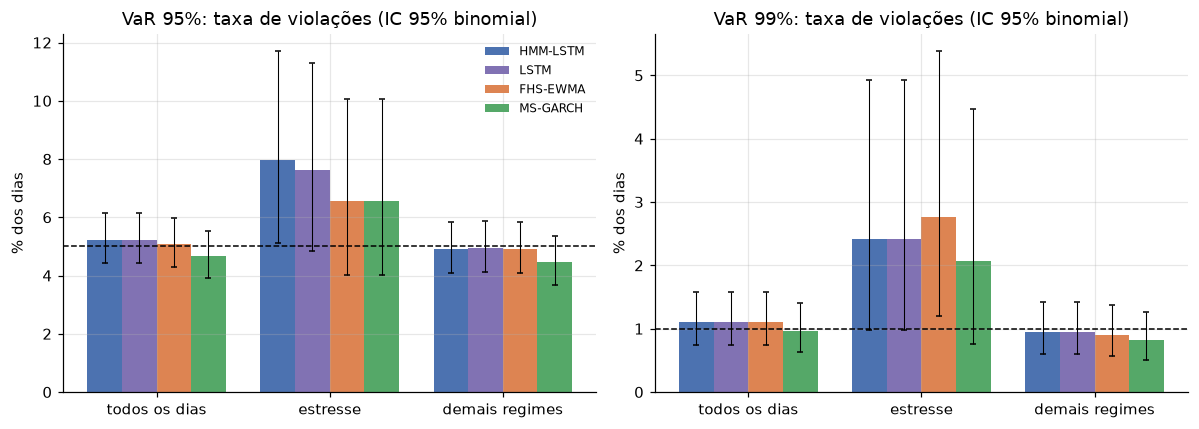

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
colors = ["#4C72B0", "#8172B3", "#DD8452", "#55A868"]
for ax, level in zip(axes, (.95, .99)):
    t = coverage[coverage.nivel == level]
    width = .2
    for i, model in enumerate(ORDER):
        s = t[t.modelo == model].set_index("segmento").reindex(list(SEGMENTS))
        x = np.arange(len(SEGMENTS)) + (i - 1.5) * width
        ax.bar(x, s.taxa * 100, width, color=colors[i], label=model)
        ax.errorbar(x, s.taxa * 100, yerr=[(s.taxa - s.taxa_ic95_inferior) * 100,
                                           (s.taxa_ic95_superior - s.taxa) * 100],
                    fmt="none", color="black", lw=.7, capsize=2)
    ax.axhline((1 - level) * 100, color="black", ls="--", lw=1)
    ax.set_xticks(range(len(SEGMENTS)), SEGMENTS.values())
    ax.set_title(f"VaR {level:.0%}: taxa de violações (IC 95% binomial)")
    ax.set_ylabel("% dos dias")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_taxa_violacoes.png", bbox_inches="tight")

No total, os quatro modelos ficam perto da taxa nominal e não há sinal de violações
agrupadas. A diferença aparece no estresse. A 95%, a HMM-LSTM chega a 8,0% de violações e o
Kupiec rejeita a cobertura, enquanto a FHS-EWMA e o MS-GARCH ficam em 6,6%. A 99%, só o
MS-GARCH não é rejeitado no estresse (2,1%). Com 289 dias, porém, os intervalos são largos:
três ou quatro violações a mais ou a menos mudam a conclusão.

## Severidade das perdas: teste do ES

In [5]:
es = coverage.copy()
es["segmento"] = es.segmento.map(SEGMENTS)
es = es.pivot_table(index=["nivel", "segmento"], columns="modelo", values=["acerbi_szekely_z2", "es_p"])
es = es.reindex(columns=pd.MultiIndex.from_product([["acerbi_szekely_z2", "es_p"], ORDER]))
es.columns = pd.MultiIndex.from_tuples([("Z2" if a == "acerbi_szekely_z2" else "p", b) for a, b in es.columns])
es.round(3)

Z2                                 p         \
                     HMM-LSTM   LSTM FHS-EWMA MS-GARCH HMM-LSTM   LSTM   
nivel segmento                                                           
0.95  demais regimes    0.012  0.013    0.021    0.130    0.337  0.418   
      estresse         -0.826 -0.746   -0.554   -0.510    0.003  0.003   
      todos os dias    -0.078 -0.067   -0.040    0.062    0.070  0.139   
0.99  demais regimes   -0.070 -0.046   -0.050    0.228    0.069  0.116   
      estresse         -2.239 -2.141   -2.542   -1.394    0.001  0.001   
      todos os dias    -0.301 -0.268   -0.315    0.056    0.005  0.008   

                                        
                     FHS-EWMA MS-GARCH  
nivel segmento                          
0.95  demais regimes    0.456    0.908  
      estresse          0.017    0.036  
      todos os dias     0.208    0.720  
0.99  demais regimes    0.121    0.853  
      estresse          0.001    0.014  
      todos os dias     0.006    0.605

O Z2 é zero quando o ES está correto e fica negativo quando as perdas além do VaR são piores
do que o modelo previa. No total, só o MS-GARCH passa a 99% (p = 0,61). Os três modelos com
erros de calibração subestimam a cauda extrema (p < 0,01). Um ano de calibração tem só 2 ou 3
erros além do quantil de 1%, pouco para descrever o que acontece ali. No estresse, todos
subestimam o ES, inclusive o MS-GARCH.

## Comparação pareada dos escores

In [6]:
def dm_table(score):
    t = dm[dm.escore == score].copy()
    t["segmento"] = t.segmento.map(SEGMENTS)
    t["par"] = t.a + " vs " + t.b
    t["leitura"] = np.where(t.dm_p < .05, np.where(t.diferenca_a_menos_b > 0, "b melhor", "a melhor"), "—")
    return t.set_index(["nivel", "segmento", "par"])[["diferenca_a_menos_b", "dm_p", "leitura"]]

quant, fz = dm_table("quantilico_var"), dm_table("fz0_var_es")
both = quant.join(fz, lsuffix="_quantil", rsuffix="_fz0")
pairs = ["HMM-LSTM vs LSTM", "HMM-LSTM vs FHS-EWMA", "HMM-LSTM vs MS-GARCH", "LSTM vs MS-GARCH",
         "FHS-EWMA vs MS-GARCH"]
both[both.index.get_level_values("par").isin(pairs)][["dm_p_quantil", "leitura_quantil", "dm_p_fz0", "leitura_fz0"]].round(4)

dm_p_quantil leitura_quantil  \
nivel segmento       par                                                  
0.95  todos os dias  HMM-LSTM vs LSTM            0.0499        b melhor   
                     HMM-LSTM vs FHS-EWMA        0.0120        b melhor   
                     HMM-LSTM vs MS-GARCH        0.0011        b melhor   
                     LSTM vs MS-GARCH            0.0202        b melhor   
                     FHS-EWMA vs MS-GARCH        0.0500               —   
      estresse       HMM-LSTM vs LSTM            0.4770               —   
                     HMM-LSTM vs FHS-EWMA        0.8870               —   
                     HMM-LSTM vs MS-GARCH        0.4799               —   
                     LSTM vs MS-GARCH            0.2027               —   
                     FHS-EWMA vs MS-GARCH        0.4041               —   
      demais regimes HMM-LSTM vs LSTM            0.0064        b melhor   
                     HMM-LSTM vs FHS-EWMA        0.0054        b melhor   
                     HMM-LSTM vs MS-GARCH        0.0003        b melhor   
                     LSTM vs MS-GARCH            0.0466        b melhor   
                     FHS-EWMA vs MS-GARCH        0.0609               —   
0.99  todos os dias  HMM-LSTM vs LSTM            0.9688               —   
                     HMM-LSTM vs FHS-EWMA        0.1512               —   
                     HMM-LSTM vs MS-GARCH        0.0005        b melhor   
                     LSTM vs MS-GARCH            0.0007        b melhor   
                     FHS-EWMA vs MS-GARCH        0.0000        b melhor   
      estresse       HMM-LSTM vs LSTM            0.9506               —   
                     HMM-LSTM vs FHS-EWMA        0.3935               —   
                     HMM-LSTM vs MS-GARCH        0.7667               —   
                     LSTM vs MS-GARCH            0.7031               —   
                     FHS-EWMA vs MS-GARCH        0.4818               —   
      demais regimes HMM-LSTM vs LSTM            0.9420               —   
                     HMM-LSTM vs FHS-EWMA        0.2384               —   
                     HMM-LSTM vs MS-GARCH        0.0000        b melhor   
                     LSTM vs MS-GARCH            0.0001        b melhor   
                     FHS-EWMA vs MS-GARCH        0.0000        b melhor   

                                           dm_p_fz0 leitura_fz0  
nivel segmento       par                                         
0.95  todos os dias  HMM-LSTM vs LSTM        0.0938           —  
                     HMM-LSTM vs FHS-EWMA    0.0249    b melhor  
                     HMM-LSTM vs MS-GARCH    0.0010    b melhor  
                     LSTM vs MS-GARCH        0.0229    b melhor  
                     FHS-EWMA vs MS-GARCH    0.0494    b melhor  
      estresse       HMM-LSTM vs LSTM        0.6352           —  
                     HMM-LSTM vs FHS-EWMA    0.7366           —  
                     HMM-LSTM vs MS-GARCH    0.4776           —  
                     LSTM vs MS-GARCH        0.2375           —  
                     FHS-EWMA vs MS-GARCH    0.4571           —  
      demais regimes HMM-LSTM vs LSTM        0.0460    b melhor  
                     HMM-LSTM vs FHS-EWMA    0.0180    b melhor  
                     HMM-LSTM vs MS-GARCH    0.0005    b melhor  
                     LSTM vs MS-GARCH        0.0477    b melhor  
                     FHS-EWMA vs MS-GARCH    0.0616           —  
0.99  todos os dias  HMM-LSTM vs LSTM        0.7690           —  
                     HMM-LSTM vs FHS-EWMA    0.5413           —  
                     HMM-LSTM vs MS-GARCH    0.0015    b melhor  
                     LSTM vs MS-GARCH        0.0065    b melhor  
                     FHS-EWMA vs MS-GARCH    0.0010    b melhor  
      estresse       HMM-LSTM vs LSTM        0.7319           —  
                     HMM-LSTM vs FHS-EWMA    0.7223           —  
                     HMM-LSTM vs MS-GARCH    0.5712       

Nos dois escores e nos dois níveis, o MS-GARCH é significativamente melhor que a HMM-LSTM no
total e nos regimes calmos (p ≤ 0,002). Também supera a LSTM nos dois níveis e a FHS-EWMA a
99%; a 95%, a diferença para a FHS-EWMA fica no limite (p ≈ 0,05). Nos regimes calmos a
95%, a HMM-LSTM perde até para a LSTM e para a FHS-EWMA (p < 0,05 nos dois escores). No
estresse, nenhuma diferença é significativa: são poucos dias para separar modelos.

## Estabilidade ao longo do tempo

Taxa de violações do VaR a 95% por ano. Isso mostra se o resultado vem de um episódio só.

model,HMM-LSTM,LSTM,FHS-EWMA,MS-GARCH,dias
ano,,,,,
2012,5.1,5.1,6.8,5.1,59
2013,3.3,3.7,4.1,3.7,246
2014,1.4,3.4,4.1,2.1,145
2015,7.1,6.6,4.1,4.1,241
2016,6.1,4.9,6.1,5.3,247
2017,4.5,3.7,3.7,3.7,244
2018,5.8,6.2,5.8,5.3,243
2019,3.7,4.5,4.9,3.3,246
2020,4.5,5.3,4.0,6.1,247


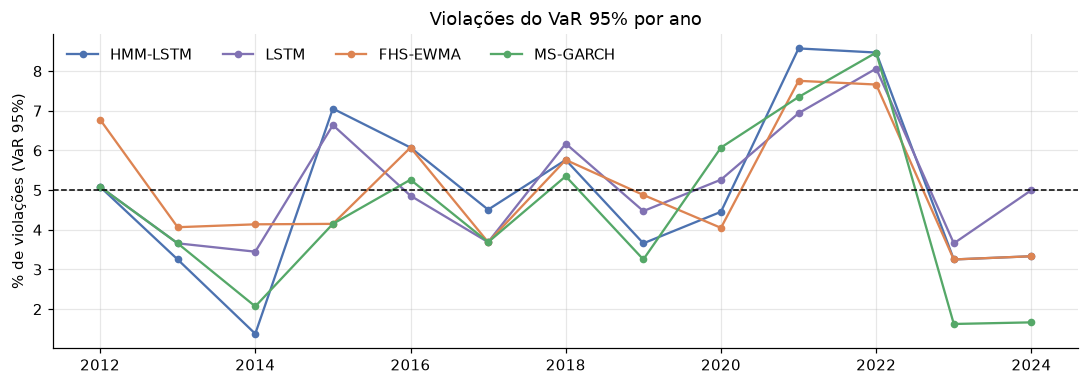

In [7]:
forecasts = pd.concat([pd.read_parquet(p) for p in sorted(RESULTS_DIR.glob("forecasts_fold*.parquet"))]
                      + [pd.read_parquet(MSGARCH_DIR / "forecasts_msgarch.parquet")], ignore_index=True)
f95 = forecasts[forecasts.confidence == .95].assign(viol=lambda d: d.actual_loss > d["var"],
                                                    ano=lambda d: d.target.dt.year)
by_year = f95.pivot_table(index="ano", columns="model", values="viol", aggfunc="mean").rename(columns=NAMES)[ORDER]
by_year["dias"] = f95[f95.model == "ms_garch"].groupby("ano").size()
display((by_year[ORDER] * 100).round(1).assign(dias=by_year.dias))

fig, ax = plt.subplots(figsize=(10, 3.6))
for model, color in zip(ORDER, colors):
    ax.plot(by_year.index, by_year[model] * 100, marker="o", ms=4, color=color, label=model)
ax.axhline(5, color="black", ls="--", lw=1)
ax.set_ylabel("% de violações (VaR 95%)")
ax.set_title("Violações do VaR 95% por ano")
ax.legend(frameon=False, ncol=4)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_violacoes_por_ano.png", bbox_inches="tight")

Em 2021 e 2022, todos os modelos ficam perto de 8%: foram anos de choques nas commodities
(geadas no café em 2021, guerra na Ucrânia em 2022) que nenhum deles antecipou. Em 2023 e
no início de 2024, o MS-GARCH fica conservador.

O número de dias por ano varia porque só entram pregões com 42 sessões completas antes da
origem. No 2º semestre de 2014, a janela 4 tem apenas 56 dias avaliados.

## Sensibilidade: MS-GARCH paramétrico

O projeto declara o VaR/ES do MS-GARCH por simulação histórica filtrada. A versão
paramétrica, que usa a própria mistura de Student-t prevista, fica como sensibilidade.

In [8]:
param = pd.read_parquet(MSGARCH_DIR / "forecasts_msgarch_param.parquet")
sessions = get_b3_trading_days(param.origin.min(), param.target.max())
rows = []
for name, frame in (("MS-GARCH FHS", forecasts[forecasts.model == "ms_garch"]), ("MS-GARCH Student-t", param)):
    for level in (.95, .99):
        s = frame[frame.confidence == level].set_index("target").sort_index()
        cov = var_coverage(s.actual_loss, s["var"], level, sessions=sessions)
        rows.append({"versão": name, "nível": level, "taxa": cov["failure_rate"],
                     "Kupiec p": cov["kupiec"]["p_value_chi2_1"], "VaR médio %": s["var"].mean() * 100})
pd.DataFrame(rows).set_index(["versão", "nível"]).round(4)

taxa  Kupiec p  VaR médio %
versão             nível                               
MS-GARCH FHS       0.95   0.0467    0.4311       1.7398
                   0.99   0.0096    0.8202       2.6884
MS-GARCH Student-t 0.95   0.0420    0.0482       1.8182
                   0.99   0.0074    0.1469       2.7560

A versão paramétrica é mais conservadora, com menos violações que a nominal. A FHS fica mais
perto da taxa esperada, o que sustenta a escolha declarada no projeto.

## As hipóteses, como formuladas no pré-projeto

- **H1**: VaR a 95% e 99% com cobertura compatível pelo teste de Kupiec, com desempenho
  superior ou equivalente ao MS-GARCH.
- **H2**: no regime de alta volatilidade, menor erro de cobertura e violações menos
  agrupadas (Christoffersen) que o MS-GARCH.
- **H3**: nos regimes de baixa volatilidade, sem perda significativa de desempenho frente ao
  benchmark pelo teste de Diebold-Mariano.

In [9]:
def cov(model, segment, level, col):
    return coverage.query("modelo == @model and segmento == @segment and nivel == @level")[col].iloc[0]

def dmp(segment, level, score="quantilico_var"):
    r = dm.query("a == 'HMM-LSTM' and b == 'MS-GARCH' and segmento == @segment and nivel == @level and escore == @score").iloc[0]
    return r.dm_p, r.diferenca_a_menos_b

rows = []
for level in (.95, .99):
    p_k = cov("HMM-LSTM", "todos", level, "kupiec_p")
    p_dm, d = dmp("todos", level)
    rows.append({"hipótese": "H1", "nível": level,
                 "evidência": f"Kupiec p={p_k:.2f}; escore vs MS-GARCH: DM p={p_dm:.4f} ({'pior' if d > 0 else 'melhor'})",
                 "resultado": "cobertura sim; equivalência ao MS-GARCH não" if p_k > .05 and p_dm < .05 and d > 0
                              else "ver evidência"})
    h, m = (cov(x, "estresse", level, "taxa") for x in ("HMM-LSTM", "MS-GARCH"))
    err_h, err_m = abs(h - (1 - level)), abs(m - (1 - level))
    ind_h, ind_m = (cov(x, "estresse", level, "independencia_p") for x in ("HMM-LSTM", "MS-GARCH"))
    rows.append({"hipótese": "H2", "nível": level,
                 "evidência": f"violações {h:.1%} vs {m:.1%}; independência p={ind_h:.2f} vs {ind_m:.2f}",
                 "resultado": "não sustentada" if err_h >= err_m else "sustentada"})
    p_dm, d = dmp("demais_regimes", level)
    rows.append({"hipótese": "H3", "nível": level, "evidência": f"DM p={p_dm:.4f}, HMM-LSTM {'pior' if d > 0 else 'melhor'}",
                 "resultado": "rejeitada" if p_dm < .05 and d > 0 else "não rejeitada"})
pd.DataFrame(rows).set_index(["hipótese", "nível"])

,,evidência,resultado
hipótese,nível,,
H1,0.95,Kupiec p=0.59; escore vs MS-GARCH: DM p=0.0011...,cobertura sim; equivalência ao MS-GARCH não
H2,0.95,violações 8.0% vs 6.6%; independência p=0.48 v...,não sustentada
H3,0.95,"DM p=0.0003, HMM-LSTM pior",rejeitada
H1,0.99,Kupiec p=0.59; escore vs MS-GARCH: DM p=0.0005...,cobertura sim; equivalência ao MS-GARCH não
H2,0.99,violações 2.4% vs 2.1%; independência p=0.58 v...,não sustentada
H3,0.99,"DM p=0.0000, HMM-LSTM pior",rejeitada


## Leitura

- **H1 se sustenta em parte.** A cobertura da HMM-LSTM é compatível com a nominal nos dois
  níveis, mas ela não é equivalente ao MS-GARCH: perde nos dois escores.
- **H2 não se sustenta.** No estresse, a HMM-LSTM viola mais que o MS-GARCH. As violações não
  aparecem agrupadas em nenhum modelo, mas isso pesa pouco com tão poucos eventos.
- **H3 é rejeitada.** Nos regimes calmos, a HMM-LSTM é significativamente pior que o
  benchmark.
- O que separa os modelos é a forma de modelar a volatilidade e a cauda. O MS-GARCH também
  supera a FHS-EWMA de média zero. A previsão de média da rede não ajuda, e a da HMM-LSTM
  atrapalha no estresse, porque o regime de estresse do treino tem média positiva
  (notebook 05).
- Esses resultados vêm de um protocolo fixado antes do teste. Variações, como a LSTM prever a
  volatilidade em vez da média ou usar caudas por regime com outro mínimo, entram como
  análises adicionais declaradas, sem substituir o resultado principal.